# Example of the aitlas toolbox in the context of semantic segmentation

The WSCS dataset can be used for image classification and semantic segmentation. This notebook showcases a semantic segmentation example using the pixel-level labels.

## Import the required packages

In [ ]:
from aitlas.datasets import WSCSSemanticSegmentationDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Show images and masks 

In [ ]:
dataset_config = {
    "data_dir" : "./data/wscs_semantic_segmentation/weakly_supervised_cropland",
}
dataset = WSCSSemanticSegmentationDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 194176


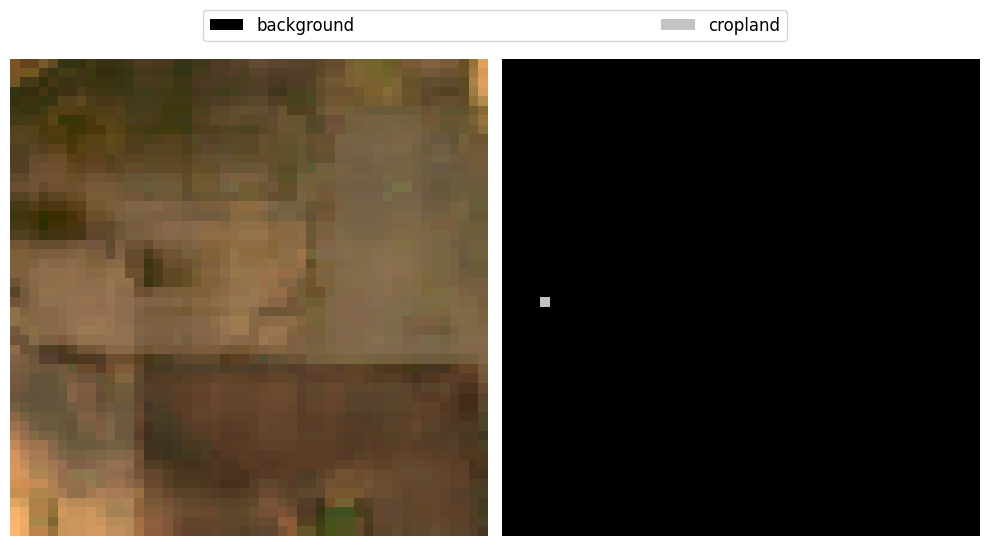

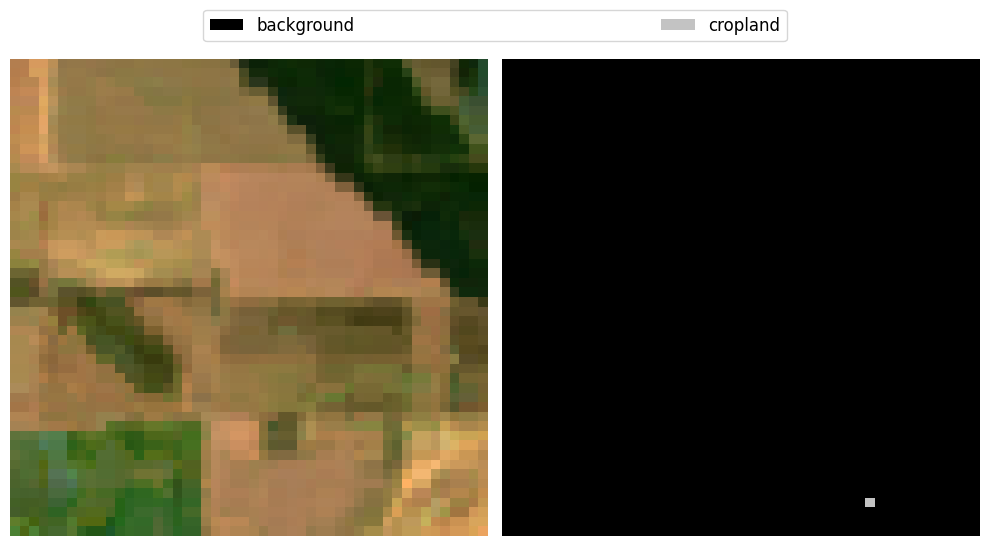

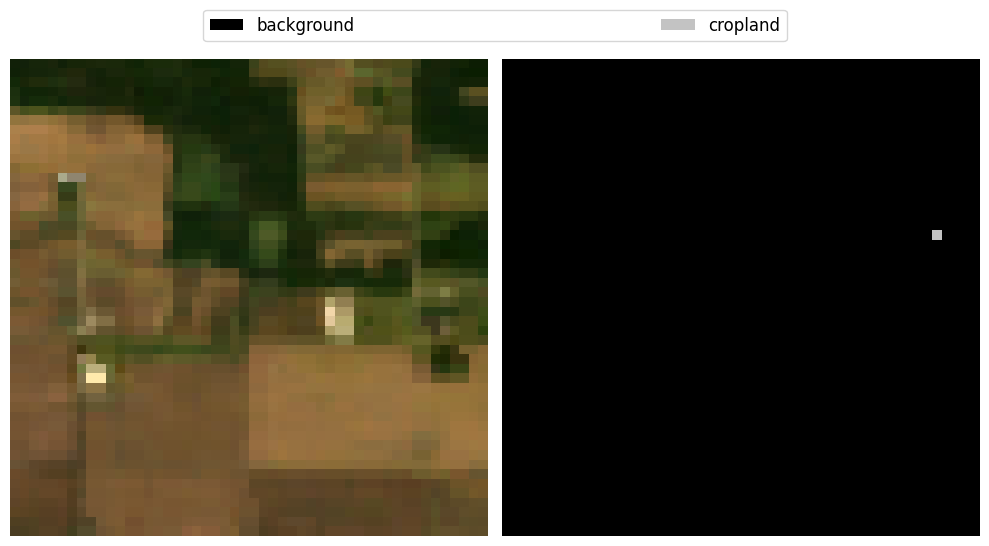

In [16]:
dataset.show_image(15);
dataset.show_image(100);
dataset.show_image(200);

In [9]:
dataset.data_distribution_table()

,Number of pixels
background,485245824.0
cropland,194176.0


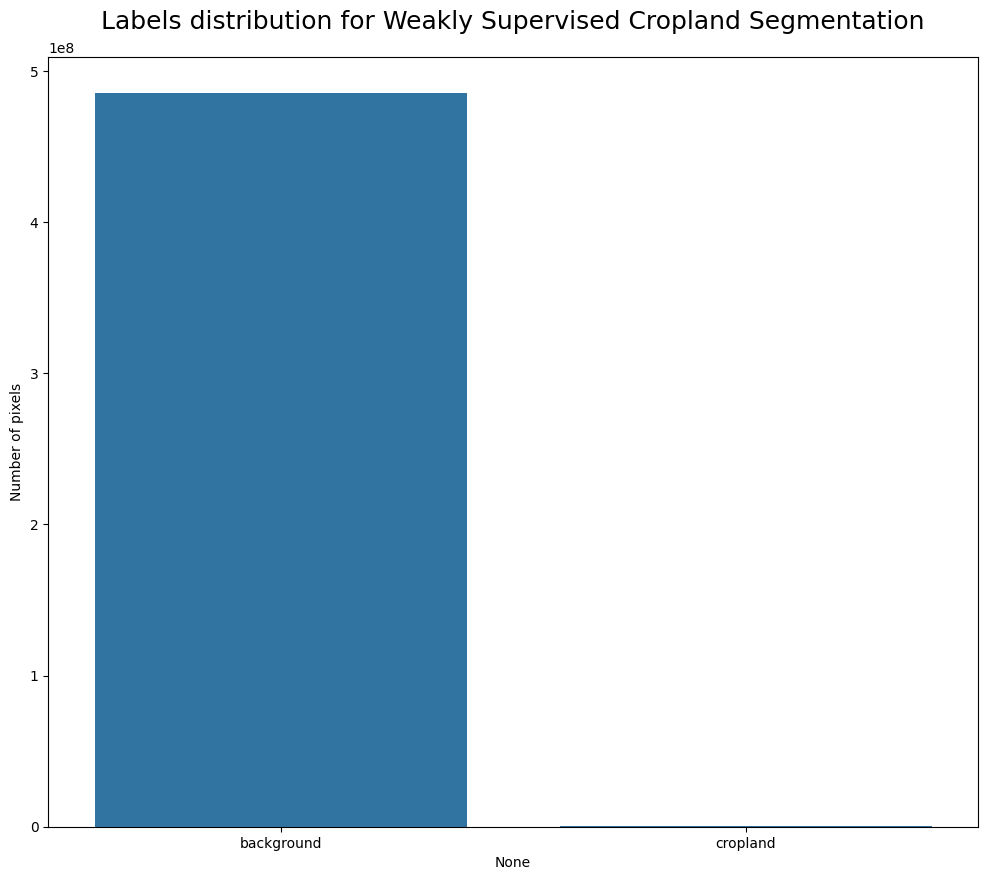

In [10]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/wscs_semantic_segmentation/weakly_supervised_cropland",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] #
}
train_dataset = WSCSSemanticSegmentationDataset(train_dataset_config)
len(train_dataset)

151700

## Create the model ##

In [ ]:
epochs = 10
model_directory = "./data/experiments/wscs_semantic_segmentation/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [13]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-10-06 11:10:31,856 INFO Starting training.
training: 100%|██████████| 4741/4741 [23:54<00:00,  3.31it/s]
2025-10-06 11:34:26,175 INFO epoch: 1, time: 1435, loss:  0.02169
testing on train set: 100%|██████████| 4741/4741 [08:39<00:00,  9.13it/s]
2025-10-06 11:43:07,292 INFO IOU:0.9984282497740452, IOU mean:0.4992141248870226, IOU per Class:[0.99842825 0.        ]
training: 100%|██████████| 4741/4741 [26:40<00:00,  2.96it/s]
2025-10-06 12:09:47,503 INFO epoch: 2, time: 1600, loss:  0.00048
testing on train set: 100%|██████████| 4741/4741 [08:24<00:00,  9.40it/s]
2025-10-06 12:18:11,841 INFO IOU:0.9984282497740452, IOU mean:0.4992141248870226, IOU per Class:[0.99842825 0.        ]
training: 100%|██████████| 4741/4741 [26:29<00:00,  2.98it/s]
2025-10-06 12:44:40,894 INFO epoch: 3, time: 1589, loss:  0.00040
testing on train set: 100%|██████████| 4741/4741 [08:30<00:00,  9.30it/s]
2025-10-06 12:53:10,953 INFO IOU:0.9984282497740452, IOU mean:0.4992141248870226, IOU per Class:[0.9984282

0.000399917408912372

## Evaluate ##

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir" : "./data/wscs_semantic_segmentation/weakly_supervised_cropland",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = WSCSSemanticSegmentationDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/wscs_semantic_segmentation/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

42476


2025-10-07 06:51:35,965 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/weak_cropland/checkpoint.pth.tar
2025-10-07 06:51:36,507 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/weak_cropland/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 10619/10619 [03:11<00:00, 55.51it/s]


[{'IOU': 0.9984292191001518,
  'IOU mean': 0.4992146095500759,
  'IOU per Class': array([0.99842922, 0.        ])}]

## Predictions ##

2025-10-07 06:58:28,472 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/weak_cropland/checkpoint.pth.tar
2025-10-07 06:58:28,966 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/weak_cropland/checkpoint.pth.tar at epoch 11


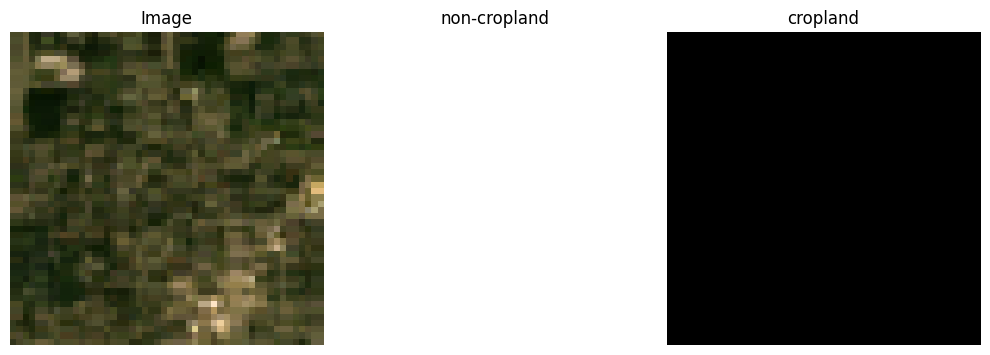

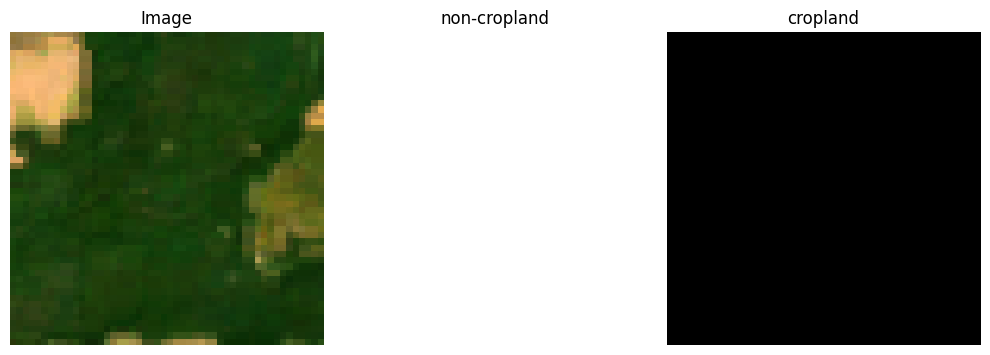

In [ ]:
test_dataset_config = {
    "data_dir" : "./data/wscs_semantic_segmentation/weakly_supervised_cropland",
    "mode": "test"
}
test_dataset = WSCSSemanticSegmentationDataset(test_dataset_config)
labels = ["non-cropland","cropland"]
transform = MinMaxNormTranspose()

model_path = "./data/experiments/wscs_semantic_segmentation/checkpoint.pth.tar"
model.load_model(model_path)

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_masks(image, labels, transform)